# 🖥️ 06 · Memory Footprint and Multi-GPU Training

> **Module 02 – Feed-Forward Networks and Backpropagation** · Notebook 6 of 6
> Course notes: page 7 *"Memory footprint of FFNN"* (4-5-3-2, 51 F.P., inference peak $51+4+5$, training $51+4+5+3+2$), page 5 *"Model size: 1 GPU / multiple … each GPU collects local updates, collect all updates together"*, *"$F_i$ has to come before $B_i$"*, page 6 *"Divide by layers … pipelined"*, *"weight matrix too big … split weight matrices"*

Everything so far fit comfortably in a laptop's memory. Real models do not: a 7-billion-parameter model cannot even be *trained* on one 80 GB GPU. This notebook answers two practical questions:

1. **Will it fit?** – estimate memory *before* running anything.
2. **If not, how do we split the work across GPUs?** – data, ZeRO, pipeline and tensor parallelism.

### 🎯 What you will learn
| # | Idea |
|---|---|
| 1 | Why **training needs more memory than inference** (the notes' 4-5-3-2 example, step by step) |
| 2 | The **16 bytes per parameter** rule for Adam training, plus activations |
| 3 | A memory estimator, checked against real NumPy arrays |
| 4 | **Data parallelism** and why averaging local gradients gives exactly the right answer |
| 5 | **Ring all-reduce**, **ZeRO / FSDP** sharding |
| 6 | **Pipeline** parallelism (divide by layers) and its "bubble" |
| 7 | **Tensor** parallelism (split one weight matrix) |

## 0 · Setup

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

# ---------- one consistent, clean plotting style for the whole notebook ----------
C = dict(blue="#2a78d6", orange="#eb6834", aqua="#1baf7a", yellow="#eda100",
         magenta="#e87ba4", green="#008300", violet="#6250d6", red="#e34948",
         ink="#0b0b0b", muted="#52514e", grid="#e6e5e1")
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.edgecolor": C["muted"], "axes.labelcolor": C["ink"], "axes.titleweight": "bold",
    "axes.titlesize": 12, "axes.labelsize": 10.5, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": C["grid"], "grid.linewidth": 0.8,
    "xtick.color": C["muted"], "ytick.color": C["muted"], "legend.frameon": False,
    "lines.linewidth": 2.0, "font.size": 10.5,
    "axes.prop_cycle": plt.cycler(color=[C[k] for k in
                       ["blue", "orange", "aqua", "yellow", "magenta", "green", "violet", "red"]]),
})
np.set_printoptions(precision=4, suppress=True)
rng = np.random.default_rng(3)

def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-z))

def softmax(Z):
    Z = Z - Z.max(axis=0, keepdims=True)
    E = np.exp(Z)
    return E / E.sum(axis=0, keepdims=True)

---
## 1 · The variables

| Symbol | Meaning | Example |
|---|---|---|
| $P$ | number of parameters (weights + biases) | 51 |
| bytes / number | float32 = **4 bytes**, float16/bfloat16 = 2 bytes | 4 |
| $N$ | batch size (examples processed together) | 256 |
| $n_l$ | neurons in layer $l$ (activations per example) | 5 |
| $K$ | number of GPUs (workers) | 8 |
| $g_k$ | gradient computed by GPU $k$ on its slice of the batch | – |
| $N_k$ | number of examples given to GPU $k$ | $N/K$ |
| $m,\ v$ | Adam's two running averages (one of each **per parameter**) | – |
| $F_i,\ B_i$ | forward / backward pass of micro-batch $i$ (notes, page 5) | – |

Network notation ($W^{[l]}$ is $n_l\times n_{l-1}$, one example per column) is the same as notebooks 01–05.

---
## 2 · Inference vs training memory: the notes' example 🧠

The 4-5-3-2 network has $(20+5)+(15+3)+(6+2)=\mathbf{51}$ parameters (notebook 01). Count the numbers that must be **in memory at the same time** (one example):

* **Inference (forward only).** Layer $l$ only needs $o^{[l-1]}$ to compute $o^{[l]}$; afterwards $o^{[l-1]}$ can be thrown away (the notes: *"no need to keep"*). The worst moment is layer 1, where the 4 inputs and 5 hidden outputs coexist → peak $51+4+5=\mathbf{60}$.
* **Training.** Backprop needs every $o^{[l]}$ again (for $\delta^{[l]}(o^{[l-1]})^\top$ and for $g'$), so **nothing can be thrown away** → peak $51+4+5+3+2=\mathbf{65}$ (notes: *"don't need output, but at peak we need all"*).

Let us simulate the forward pass and track the live count.

In [2]:
sizes = [4, 5, 3, 2]
P = sum(sizes[l] * sizes[l - 1] + sizes[l] for l in range(1, len(sizes)))

def live_memory(sizes, keep_all):
    """Numbers alive in memory after each event of a forward pass (weights always loaded)."""
    timeline, live = [("load weights", P)], {}
    live["x"] = sizes[0]; timeline.append(("input x", P + sum(live.values())))
    names = ["x"] + [f"o{l}" for l in range(1, len(sizes))]
    for l in range(1, len(sizes)):
        live[names[l]] = sizes[l]                                    # compute o^[l]
        timeline.append((f"compute {names[l]}", P + sum(live.values())))
        if not keep_all:
            del live[names[l - 1]]                                   # inference: drop o^[l-1]
            timeline.append((f"free {names[l-1]}", P + sum(live.values())))
    return timeline

inf = live_memory(sizes, keep_all=False)
trn = live_memory(sizes, keep_all=True)
print(f"parameters P = {P}")
print(f"inference peak = {max(v for _, v in inf)}   (= 51 + 4 + 5)")
print(f"training  peak = {max(v for _, v in trn)}   (= 51 + 4 + 5 + 3 + 2)")

parameters P = 51
inference peak = 60   (= 51 + 4 + 5)
training  peak = 65   (= 51 + 4 + 5 + 3 + 2)


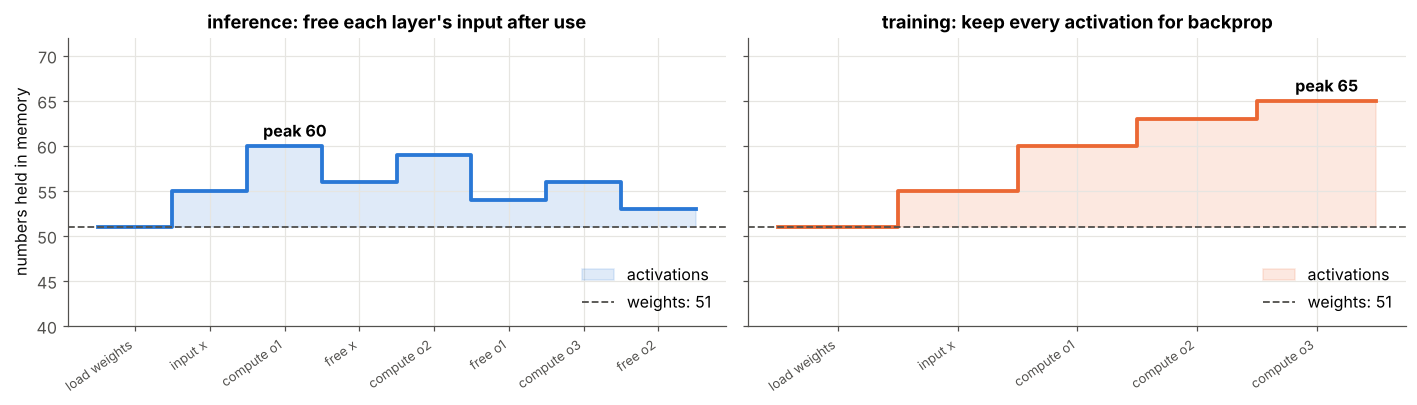

In [3]:
fig, axs = plt.subplots(1, 2, figsize=(13, 3.8), sharey=True)
for ax, tl, title, col in [(axs[0], inf, "inference: free each layer's input after use", C["blue"]),
                           (axs[1], trn, "training: keep every activation for backprop", C["orange"])]:
    vals = [v for _, v in tl]
    xs_, ys_ = range(len(vals) + 1), vals + [vals[-1]]                 # one extra point so the last step shows
    ax.step(xs_, ys_, where="post", color=col, lw=2.5)
    ax.fill_between(xs_, P, ys_, step="post", color=col, alpha=0.15, label="activations")
    ax.axhline(P, color=C["muted"], ls="--", lw=1.2, label=f"weights: {P}")
    pk = int(np.argmax(vals)); ax.annotate(f"peak {vals[pk]}", (pk + 0.5, vals[pk]), textcoords="offset points", xytext=(-14, 6), fontweight="bold")
    ax.set_xticks(np.arange(len(tl)) + 0.5, [n for n, _ in tl], rotation=35, ha="right", fontsize=8.5)
    ax.set_title(title); ax.set_ylim(40, 72); ax.legend(loc="lower right")
axs[0].set_ylabel("numbers held in memory")
plt.tight_layout(); plt.show()

---
## 3 · The full training bill: 16 bytes per parameter 🧾

During training, **every parameter** needs several numbers stored next to it:

| item | why it exists | float32 bytes / param |
|---|---|---|
| weight | the parameter itself | 4 |
| gradient $\partial E/\partial\theta$ | produced by backprop, consumed by the update | 4 |
| optimiser state | plain SGD: none; momentum: $v$; **Adam: $m$ and $v$** | 0 / 4 / **8** |
| **total (Adam)** | | **16** |

$$\boxed{\text{memory}\approx 16\ P\ \text{bytes}\ +\ \underbrace{N\cdot\Big(n_0+2\sum_{l\ge1}n_l\Big)\cdot 4}_{\text{activations: }x\text{, and }net^{[l]},o^{[l]}\text{ for every layer}}}$$

The parameter part is **fixed**; the activation part **grows with the batch size $N$**.

In [4]:
OPT_STATES = {"sgd": 0, "momentum": 1, "adam": 2}            # extra numbers stored per parameter


def n_params(sizes):
    return sum(sizes[l] * sizes[l - 1] + sizes[l] for l in range(1, len(sizes)))


def activation_numbers(sizes, batch):
    """Numbers stored for backprop: the input X plus net^[l] and o^[l] of every layer."""
    return batch * (sizes[0] + 2 * sum(sizes[1:]))


def training_memory(sizes, batch, optimizer="adam", bytes_per=4):
    P = n_params(sizes)
    return dict(weights=P * bytes_per,
                grads=P * bytes_per,
                optimizer=OPT_STATES[optimizer] * P * 4,      # optimiser states are kept in fp32
                activations=activation_numbers(sizes, batch) * bytes_per)

In [5]:
sizes = [784, 4096, 4096, 10]
mem = training_memory(sizes, batch=256)
print(f"network {sizes}: {n_params(sizes):,} parameters, batch 256, Adam, float32")
for k, v in mem.items():
    print(f"  {k:<12}{v / 1e6:10.2f} MB")
print(f"  {'TOTAL':<12}{sum(mem.values()) / 1e6:10.2f} MB")

network [784, 4096, 4096, 10]: 20,037,642 parameters, batch 256, Adam, float32
  weights          80.15 MB
  grads            80.15 MB
  optimizer       160.30 MB
  activations      17.60 MB
  TOTAL           338.20 MB


### ✅ Check the estimate against real arrays
Allocate float32 weights, gradients, Adam states and a real forward cache, then count their bytes.

In [6]:
B = 256
W = [rng.normal(0, 0.02, (sizes[l], sizes[l - 1])).astype(np.float32) for l in range(1, len(sizes))]
b = [np.zeros((n, 1), np.float32) for n in sizes[1:]]
X = rng.normal(size=(sizes[0], B)).astype(np.float32)

O, store = X, [X]                                           # forward pass storing net and o
for l in range(len(W)):
    NET = W[l] @ O + b[l]
    O = softmax(NET) if l == len(W) - 1 else np.maximum(0, NET)
    store += [NET, O]

real = dict(weights=sum(a.nbytes for a in W + b),
            grads=sum(a.nbytes for a in W + b),               # gradients have the same shapes
            optimizer=2 * sum(a.nbytes for a in W + b),       # Adam: m and v
            activations=sum(a.nbytes for a in store))
for k in mem:
    print(f"{k:<12} estimate = {mem[k] / 1e6:9.2f} MB | measured = {real[k] / 1e6:9.2f} MB | equal: {mem[k] == real[k]}")

weights      estimate =     80.15 MB | measured =     80.15 MB | equal: True
grads        estimate =     80.15 MB | measured =     80.15 MB | equal: True
optimizer    estimate =    160.30 MB | measured =    160.30 MB | equal: True
activations  estimate =     17.60 MB | measured =     17.60 MB | equal: True


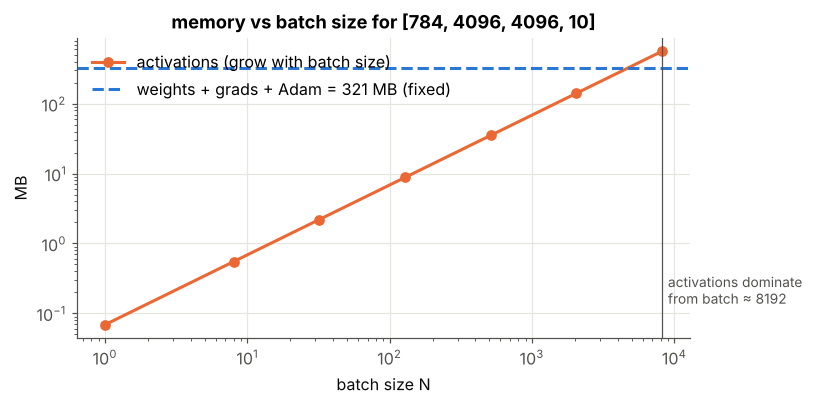

In [7]:
batches = np.array([1, 8, 32, 128, 512, 2048, 8192])
act = np.array([training_memory(sizes, bs)["activations"] for bs in batches]) / 1e6
fixed = sum(v for k, v in training_memory(sizes, 1).items() if k != "activations") / 1e6
fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.loglog(batches, act, "o-", color=C["orange"], label="activations (grow with batch size)")
ax.axhline(fixed, color=C["blue"], ls="--", label=f"weights + grads + Adam = {fixed:.0f} MB (fixed)")
cross = batches[np.argmax(act > fixed)]
ax.axvline(cross, color=C["muted"], lw=0.8); ax.text(cross * 1.1, act.min() * 2, f"activations dominate\nfrom batch ≈ {cross}", color=C["muted"], fontsize=9)
ax.set_xlabel("batch size N"); ax.set_ylabel("MB"); ax.set_title(f"memory vs batch size for {sizes}"); ax.legend(loc="upper left")
plt.tight_layout(); plt.show()

---
## 4 · Scaling up: will an LLM fit? 🐘

Ignoring activations, Adam training costs 16 bytes per parameter (mixed precision also lands at about 16: 2+2 bytes for fp16 weights and gradients, plus 4+4+4 for fp32 master weights, $m$ and $v$).

In [8]:
for name, P_ in [("125M (GPT-2 small)", 125e6), ("1B", 1e9), ("7B", 7e9), ("70B", 70e9)]:
    gb = 16 * P_ / 1e9
    print(f"{name:<19} → {gb:8,.1f} GB of training state   ({gb / 80:5.2f} × an 80 GB GPU)")

125M (GPT-2 small)  →      2.0 GB of training state   ( 0.03 × an 80 GB GPU)
1B                  →     16.0 GB of training state   ( 0.20 × an 80 GB GPU)
7B                  →    112.0 GB of training state   ( 1.40 × an 80 GB GPU)
70B                 →  1,120.0 GB of training state   (14.00 × an 80 GB GPU)


A 7B model needs **112 GB** just for its training state – more than any single GPU. We *must* split it. The notes list the two axes along which to split: **data size** and **model size**.

---
## 5 · Data parallelism: copy the model, split the data 📋

The notes: *"Each GPU collects local updates. Collect all updates together."*

Every GPU holds a **full copy** of the model, takes a different slice of the mini-batch ($N_k$ examples), runs forward + backward **independently**, and then the gradients are **averaged** (an *all-reduce*).

**Why is the result exactly right?** Our loss is a mean over examples, so its gradient is a mean of per-example gradients, and a mean can be computed piece by piece:

$$g_{\text{full}}=\frac1N\sum_{n=1}^{N}g_n=\sum_{k=1}^{K}\frac{N_k}{N}\underbrace{\Big(\frac1{N_k}\sum_{n\in\text{GPU }k}g_n\Big)}_{g_k}$$

In [9]:
def init_params(sizes, rng):
    return [(rng.normal(0, np.sqrt(2 / sizes[l - 1]), (sizes[l], sizes[l - 1])), np.zeros((sizes[l], 1)))
            for l in range(1, len(sizes))]


def grads_for(params, X, T):
    """Mean-loss gradients ∂E/∂W, ∂E/∂b of a ReLU / softmax MLP on (X, T); columns = examples."""
    O, cache, L = X, [(None, X)], len(params)
    for l, (W, b) in enumerate(params, 1):                     # forward, storing net and o
        NET = W @ O + b
        O = softmax(NET) if l == L else np.maximum(0, NET)
        cache.append((NET, O))
    delta, out = (T - O) / X.shape[1], [None] * L                # δ^[L] = (T - P) / N
    for l in range(L, 0, -1):                                    # backward
        out[l - 1] = (-delta @ cache[l - 1][1].T, -delta.sum(1, keepdims=True))
        if l > 1:
            delta = (params[l - 1][0].T @ delta) * (cache[l - 1][0] > 0)
    return out


flat = lambda gr: np.concatenate([np.concatenate([dW.ravel(), db.ravel()]) for dW, db in gr])

In [10]:
sizes = [20, 32, 16, 4]
params = init_params(sizes, rng)
N, K = 64, 4
X = rng.normal(size=(20, N)); T = np.eye(4)[:, rng.integers(0, 4, N)]

g_full = flat(grads_for(params, X, T))                          # one device, whole batch
shards = np.array_split(np.arange(N), K)                        # GPU k gets N/K examples
g_local = [flat(grads_for(params, X[:, s], T[:, s])) for s in shards]   # independent backward passes
g_avg = sum(len(s) / N * g for s, g in zip(shards, g_local))    # all-reduce: weighted average

print(f"{K} workers × {N // K} examples each")
print("max |single-GPU − data-parallel| =", np.abs(g_full - g_avg).max())

4 workers × 16 examples each
max |single-GPU − data-parallel| = 5.551115123125783e-17


Identical up to floating-point rounding. ✅ Data parallelism changes **where** the work happens, not **what** is computed.

### Ring all-reduce: how the averaging is really done 💍
Sending every gradient to one "master" GPU makes that GPU a bottleneck (it receives $(K-1)\times$ the gradient). In a **ring all-reduce**, the gradient is cut into $K$ chunks that travel around a circle of GPUs: first each chunk is summed as it passes (*reduce-scatter*), then the finished sums are passed around (*all-gather*). Each GPU sends only $\frac{2(K-1)}{K}$ times the gradient size – **almost independent of $K$**.

every worker ends with the full sum: True


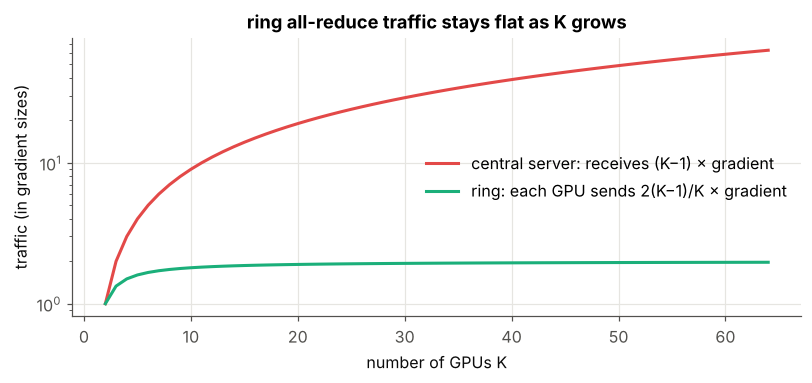

In [11]:
def ring_allreduce(vectors):
    """Simulate ring all-reduce over K workers. Returns what every worker holds at the end."""
    K = len(vectors)
    ch = [np.array_split(v.copy(), K) for v in vectors]          # ch[worker][chunk]
    for step in range(K - 1):                                    # phase 1: reduce-scatter
        sends = [(w, (w - step) % K) for w in range(K)]
        msgs = [ch[w][c].copy() for w, c in sends]
        for (w, c), msg in zip(sends, msgs):
            ch[(w + 1) % K][c] = ch[(w + 1) % K][c] + msg        # neighbour adds the incoming chunk
    for step in range(K - 1):                                    # phase 2: all-gather
        sends = [(w, (w + 1 - step) % K) for w in range(K)]
        msgs = [ch[w][c].copy() for w, c in sends]
        for (w, c), msg in zip(sends, msgs):
            ch[(w + 1) % K][c] = msg                             # neighbour overwrites with the full sum
    return [np.concatenate(c) for c in ch]

vecs = [rng.normal(size=1003) for _ in range(5)]
out = ring_allreduce(vecs)
print("every worker ends with the full sum:", all(np.allclose(o, sum(vecs)) for o in out))

Ks = np.arange(2, 65)
fig, ax = plt.subplots(figsize=(7.5, 3.6))
ax.plot(Ks, Ks - 1, color=C["red"], label="central server: receives (K−1) × gradient")
ax.plot(Ks, 2 * (Ks - 1) / Ks, color=C["aqua"], label="ring: each GPU sends 2(K−1)/K × gradient")
ax.set_xlabel("number of GPUs K"); ax.set_ylabel("traffic (in gradient sizes)"); ax.set_yscale("log")
ax.set_title("ring all-reduce traffic stays flat as K grows"); ax.legend()
plt.tight_layout(); plt.show()

### ZeRO / FSDP: stop storing identical copies 🧩
In plain data parallelism every GPU stores the *same* weights, gradients and Adam states – wasteful. **ZeRO** shards them: each GPU keeps only $1/K$ of a component and fetches the rest when needed.

| strategy | weights | gradients | Adam states |
|---|---|---|---|
| plain data parallel (DDP) | full | full | full |
| ZeRO-1 | full | full | **1/K** |
| ZeRO-2 | full | **1/K** | **1/K** |
| ZeRO-3 / FSDP | **1/K** | **1/K** | **1/K** |

DDP       112.0 GB per GPU   does NOT fit on an 80 GB GPU
ZeRO-1     63.0 GB per GPU   fits on an 80 GB GPU
ZeRO-2     38.5 GB per GPU   fits on an 80 GB GPU
ZeRO-3     14.0 GB per GPU   fits on an 80 GB GPU


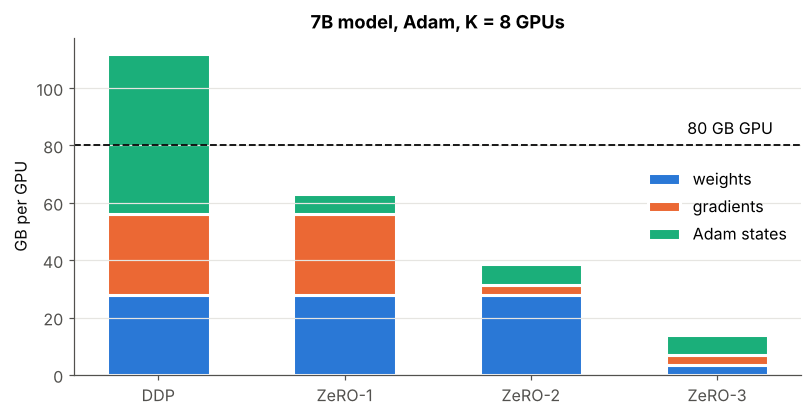

In [12]:
def per_gpu_gb(P, K, strategy):
    w, g, o = 4 * P, 4 * P, 8 * P                                # bytes: weights, grads, Adam m+v
    if strategy in ("ZeRO-1", "ZeRO-2", "ZeRO-3"): o /= K
    if strategy in ("ZeRO-2", "ZeRO-3"):           g /= K
    if strategy == "ZeRO-3":                       w /= K
    return w / 1e9, g / 1e9, o / 1e9

P7, K = 7e9, 8
strategies = ["DDP", "ZeRO-1", "ZeRO-2", "ZeRO-3"]
parts = np.array([per_gpu_gb(P7, K, s) for s in strategies])
for s, tot in zip(strategies, parts.sum(axis=1)):
    print(f"{s:<7} {tot:7.1f} GB per GPU   {'fits' if tot <= 80 else 'does NOT fit'} on an 80 GB GPU")

fig, ax = plt.subplots(figsize=(7.5, 3.9))
bottom = np.zeros(len(strategies))
for j, (lab, col) in enumerate(zip(["weights", "gradients", "Adam states"], [C["blue"], C["orange"], C["aqua"]])):
    ax.bar(strategies, parts[:, j], bottom=bottom, label=lab, color=col, width=0.55, edgecolor="white", linewidth=2)
    bottom += parts[:, j]
ax.axhline(80, color=C["ink"], ls="--", lw=1.2); ax.text(3.3, 84, "80 GB GPU", ha="right")
ax.set_ylabel("GB per GPU"); ax.set_title(f"7B model, Adam, K = {K} GPUs"); ax.legend(); ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

---
## 6 · Pipeline parallelism: divide by layers 🏭

When the model itself does not fit, split it **by layers** (notes, page 6): GPU 1 holds the first layers, GPU 2 the next, and so on. Activations flow forward from GPU to GPU, blame ($\delta$) flows back.

**Why does backprop still work?** Notebook 04: each layer's update needs only *"info about next layer and previous layer"*. GPU $s$ needs only the activations coming in and the $\delta$ coming back from GPU $s+1$ – local information.

In [13]:
sizes_big = [1024, 8192, 8192, 8192, 8192, 1000]
n_dev, micro = 2, 64
layers = list(zip(sizes_big[:-1], sizes_big[1:]))
split = np.array_split(np.arange(len(layers)), n_dev)
for d, idx in enumerate(split):
    Pd = sum(layers[i][0] * layers[i][1] + layers[i][1] for i in idx)
    print(f"GPU {d}: layers {[int(i) + 1 for i in idx]} → {Pd / 1e6:6.1f} M params = {16 * Pd / 1e9:5.2f} GB (fp32 + Adam)")
    if d < n_dev - 1:
        w_out = layers[idx[-1]][1]
        print(f"        sends o^[{idx[-1] + 1}] ({w_out}×{micro}) = {w_out * micro * 4 / 1e6:.1f} MB forward, "
              f"receives δ of the same size backward, per micro-batch")

GPU 0: layers [1, 2, 3] →  142.6 M params =  2.28 GB (fp32 + Adam)
        sends o^[3] (8192×64) = 2.1 MB forward, receives δ of the same size backward, per micro-batch
GPU 1: layers [4, 5] →   75.3 M params =  1.20 GB (fp32 + Adam)


### The pipeline "bubble" and micro-batches
The notes: *"$F_i$ has to come before $B_i$"* – a micro-batch's backward pass can only start after its forward pass has gone through **all** stages. With one big batch, each GPU sits idle while the others work. Splitting the batch into **micro-batches** $F_1,F_2,\dots$ lets the stages overlap (the GPipe schedule):

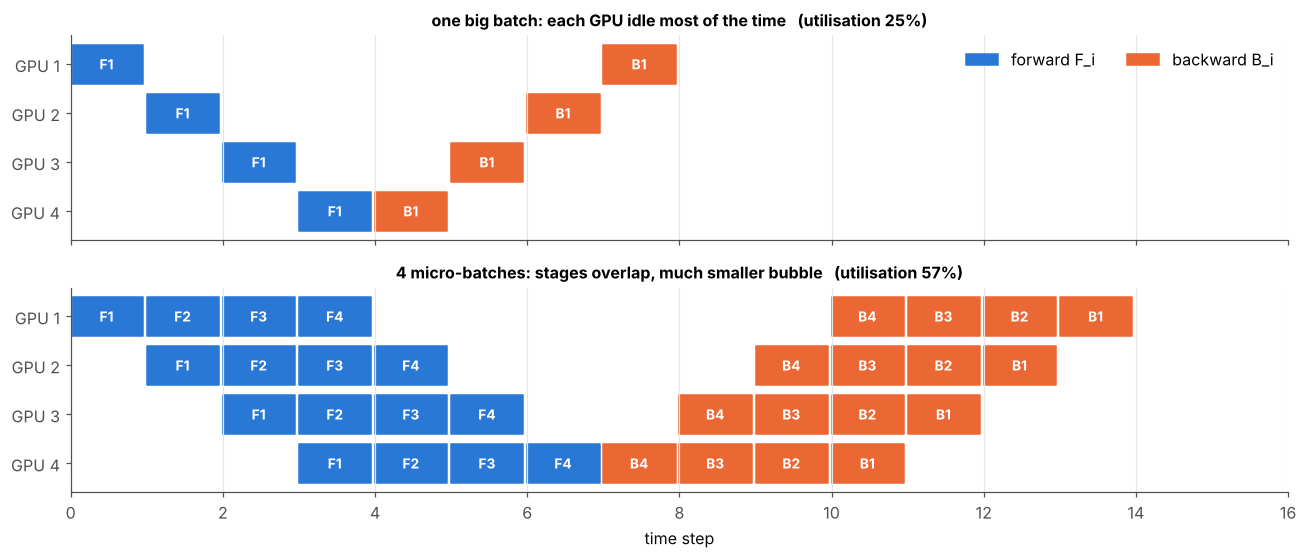

In [14]:
def schedule(S, M):
    """GPipe-style schedule: forwards of M micro-batches through S stages, then backwards in reverse."""
    jobs = []                                                     # (stage, start, kind, micro-batch)
    for m in range(M):
        for s in range(S):
            jobs.append((s, m + s, "F", m + 1))
    t0 = M + S - 1
    for m in reversed(range(M)):
        for s in reversed(range(S)):
            jobs.append((s, t0 + (M - 1 - m) + (S - 1 - s), "B", m + 1))
    return jobs, t0 + M + S - 1

S = 4
fig, axs = plt.subplots(2, 1, figsize=(12, 5.2), sharex=True)
for ax, M, title in [(axs[0], 1, "one big batch: each GPU idle most of the time"),
                     (axs[1], 4, "4 micro-batches: stages overlap, much smaller bubble")]:
    jobs, T_total = schedule(S, M)
    for s, t, kind, m in jobs:
        ax.broken_barh([(t, 0.95)], (S - 1 - s - 0.4, 0.8), color=C["blue"] if kind == "F" else C["orange"])
        ax.text(t + 0.47, S - 1 - s, f"{kind}{m}", ha="center", va="center", color="white", fontsize=9, fontweight="bold")
    busy = 2 * S * M / (S * T_total)
    ax.set_yticks(range(S), [f"GPU {S - i}" for i in range(S)]); ax.set_title(f"{title}   (utilisation {busy:.0%})", fontsize=10.5)
    ax.grid(axis="y", visible=False)
axs[1].set_xlabel("time step"); axs[1].set_xlim(0, 16)
axs[0].legend(handles=[plt.Rectangle((0, 0), 1, 1, color=C["blue"]), plt.Rectangle((0, 0), 1, 1, color=C["orange"])],
              labels=["forward F_i", "backward B_i"], loc="upper right", ncol=2)
plt.tight_layout(); plt.show()

Utilisation rises from 25% to about 57% here, and approaches 100% as the number of micro-batches grows.

---
## 7 · Tensor parallelism: split one weight matrix ✂️

The notes: *"Weight matrix too big. Layer so wide [we can't] fit even 1 layer weight matrix → split weight matrices."* Because $net=Wo+b$ treats each **row** of $W$ (each neuron) independently, we can give half the rows to each GPU and concatenate the results. Splitting by **columns** instead gives partial sums that must be added.

In [15]:
W_big = rng.normal(size=(8, 6)); b_big = rng.normal(size=(8, 1)); x_in = rng.normal(size=(6, 3))
full = W_big @ x_in + b_big

# row split: GPU 0 computes neurons 0-3, GPU 1 neurons 4-7 → concatenate
row_parts = [W_big[:4] @ x_in + b_big[:4], W_big[4:] @ x_in + b_big[4:]]
# column split: each GPU sees half of the inputs → partial sums are added (an all-reduce)
col_parts = [W_big[:, :3] @ x_in[:3], W_big[:, 3:] @ x_in[3:]]

print("row split    (concatenate) equals full:", np.allclose(np.vstack(row_parts), full))
print("column split (sum)         equals full:", np.allclose(col_parts[0] + col_parts[1] + b_big, full))

row split    (concatenate) equals full: True
column split (sum)         equals full: True


---
## 8 · Summary 📌

| technique | splits | communicates | solves |
|---|---|---|---|
| **data parallel** | the batch | gradients (all-reduce) | throughput |
| **ZeRO / FSDP** | optimiser states, gradients, weights | shards on demand | memory per GPU |
| **pipeline parallel** (divide by layers) | layers | activations forward, $\delta$ backward | model too big for one GPU |
| **tensor parallel** (split weight matrices) | each matrix | partial results | a single layer too big |

| fact | value |
|---|---|
| notes' 4-5-3-2 | 51 params; inference peak 60 numbers; training peak 65 |
| Adam training | 16 bytes / parameter + activations ($\propto$ batch size) |
| 7B model | 112 GB with plain DDP → 14 GB per GPU with ZeRO-3 on 8 GPUs |
| ring all-reduce | $2(K-1)/K$ gradient sizes sent per GPU |

### ✍️ Try it yourself
1. **Gradient checkpointing:** store only every $\sqrt L$-th layer's activations and recompute the rest during backward. Add it to `activation_numbers`. How much memory is saved for a 16-layer network?
2. Extend `per_gpu_gb` for bf16 mixed precision (2-byte weights and grads, plus 4-byte master weights).
3. **Gradient accumulation:** prove with `grads_for` that 4 micro-batches of 16 (gradients averaged) give exactly the gradient of one batch of 64.
4. In `schedule`, how does utilisation change with $M=8$ and $M=16$? Derive the formula $\frac{M}{M+S-1}$.

**Module 02 complete! 🎉** Next module: **Text to Numbers and Word Embeddings** (word2vec, pages 6–13 of the notes).